# Minería de Datos Visual y Analítica Predictiva sobre Microdatos de la Encuesta de Hogares (INE Bolivia)
### CASO 3: Discriminación, Seguridad Ciudadana y Factores Sociodemográficos

**Programa:** Maestría / Especialización en Ciencia de Datos e Inteligencia Artificial  
**Metodología Guía:** Cross-Industry Standard Process for Data Mining (CRISP-DM)  
**Entorno Tecnológico:** Python 3.12, DuckDB, Pyreadstat, Scikit-Learn, XGBoost, SHAP, Sweetviz, ydata-profiling, Seaborn, Plotly.

---

### Metodología CRISP-DM implementada en este Notebook:
1. **Fase 1: Comprensión del Negocio (Business Understanding):** Planteamiento del problema sociodemográfico, formulación de hipótesis y criterios de éxito.
2. **Fase 2: Comprensión de los Datos (Data Understanding):** Ingesta analítica con DuckDB en memoria (`:memory:`), perfilado exploratorio automatizado (Sweetviz vs. ydata-profiling) y benchmarking.
3. **Fase 3: Preparación de los Datos (Data Preparation):** Normalización relacional (FOLIO y NRO), tratamiento de valores atípicos, pipelines de imputación, codificación One-Hot y escalado estandarizado.
4. **Fase 4: Modelado (Modeling):** Entrenamiento supervisado con Random Forest y XGBoost considerando el desbalanceo de clases (`class_weight='balanced'`).
5. **Fase 5: Evaluación (Evaluation):** Análisis comparativo riguroso (Accuracy, Precision, Recall, F1-Score Macro/Weighted, Matriz de Confusión y ROC-AUC).
6. **Fase 6: Despliegue y Explicabilidad (Deployment & XAI):** Interpretabilidad global y local mediante SHAP (TreeExplainer, Beeswarm e Importance Barplot).


## 0. Configuración del Entorno y Carga de Módulos


In [1]:
import os
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Asegurar visibilidad de la carpeta 'src'
current_dir = Path(os.getcwd())
if (current_dir.parent / "src").exists():
    src_path = str(current_dir.parent / "src")
elif (current_dir / "src").exists():
    src_path = str(current_dir / "src")
else:
    src_path = "src"

if src_path not in sys.path:
    sys.path.append(src_path)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Importar módulos de la arquitectura
from ingesta import DataIngestionPipeline, SAVFileReader, DuckDBRelationalProcessor
from eda import AutomatedEDAGenerator
from visualizacion import SociodemographicVisualizer
from modelado import PredictiveModelPipeline

print("✓ Módulos arquitectónicos cargados con éxito desde:", src_path)


✓ Módulos arquitectónicos cargados con éxito desde: D:\proyectos\tareamaestria\src


## 1. Fase 1 y 2: Ingesta de Datos Relacionales con DuckDB y Persistencia Parquet
En esta sección se ejecutan las siguientes operaciones:
1. Inspección y lectura de microdatos en formato SPSS (`.sav`) ubicados en `data/raw/` mediante `pyreadstat`.
2. Si los archivos aún no han sido copiados a `data/raw/`, el pipeline genera automáticamente un dataset sintético representativo calibrado con los códigos oficiales del INE Bolivia para posibilitar la ejecución integral.
3. Carga y registro de tablas en una base de datos analítica **DuckDB en memoria (`:memory:`)**.
4. Ejecución de consultas SQL de consolidación relacional mediante llaves compuestas `FOLIO` (hogar) y `NRO` (persona).
5. Exportación eficiente del dataset consolidado a formato columnar `data/processed/dataset_consolidado.parquet`.


In [2]:
pipeline = DataIngestionPipeline()

try:
    print("Iniciando pipeline de ingesta relacional...")
    df = pipeline.run(force_synthetic_if_empty=True)
    print(f"✓ Ingesta completada con éxito. Dimensiones del dataset: {df.shape[0]} filas x {df.shape[1]} columnas.")
except Exception as e:
    print(f"Error durante la ingesta: {e}")
    raise

# Visualización preliminar del dataset consolidado
df.head(10)


2026-11-10 23:48:14,339 [INFO] Archivos .sav descubiertos en data\raw: ['discriminacion', 'equipamiento', 'gastos_alimentarios', 'gastos_no_alimentarios', 'persona', 'seguridad_alimentaria', 'vivienda']


Iniciando pipeline de ingesta relacional...


2026-11-10 23:48:15,606 [INFO] Archivo EH2025_Persona.sav leído con éxito (encoding: latin1, registros: 39485, columnas: 276)


2026-11-10 23:48:15,639 [INFO] Tabla 'persona' registrada en DuckDB con 39485 registros.


2026-11-10 23:48:15,706 [INFO] Archivo EH2025_Discriminacion.sav leído con éxito (encoding: latin1, registros: 12358, columnas: 44)


2026-11-10 23:48:15,729 [INFO] Tabla 'discriminacion' registrada en DuckDB con 12358 registros.


... (5 outputs left out)

2026-11-10 23:48:16,304 [INFO] Ejecutando consolidación relacional avanzada Persona + Discriminación (Caso 3)...


2026-11-10 23:48:16,388 [INFO] Dataset consolidado exportado exitosamente a data\processed\dataset_consolidado.parquet (12358 filas, 21 columnas).


✓ Ingesta completada con éxito. Dimensiones del dataset: 12358 filas x 21 columnas.


,folio,nro,depto,depto_nombre,area,sexo,edad,anios_estudio,nivel_educativo,etnicidad_indigena,...,ingreso_laboral,horas_trabajo,nivel_pobreza,tiene_computadora,tiene_refrigerador,tipo_vivienda,material_paredes,percepcion_inseguridad,victima_inseguridad,victima_discriminacion
0,111-000005-A-0011,2,1,Chuquisaca,1,2,39,6.0,1,2,...,1500.000000,30.00,1,0,1,1.0,1.0,3,0,0
1,111-000005-A-0021,4,1,Chuquisaca,1,2,20,13.0,3,2,...,0.000000,0.00,1,1,1,1.0,1.0,3,0,0
2,111-000005-A-0041,1,1,Chuquisaca,1,2,45,2.0,1,2,...,1299.000000,73.50,1,0,0,4.0,1.0,2,0,1
3,111-000005-A-0051,2,1,Chuquisaca,1,2,18,12.0,2,1,...,1081.859985,46.50,1,0,0,4.0,1.0,3,1,1
4,111-000005-A-0061,3,1,Chuquisaca,1,2,15,8.0,2,2,...,0.000000,0.00,1,0,0,4.0,1.0,3,0,0
5,111-000005-A-0071,2,1,Chuquisaca,1,2,36,12.0,2,2,...,0.000000,0.00,1,0,1,4.0,1.0,2,0,0
6,111-000005-A-0081,1,1,Chuquisaca,1,2,48,6.0,1,1,...,2369.500000,43.75,0,1,1,1.0,1.0,3,0,0
7,111-000005-A-0091,3,1,Chuquisaca,1,1,18,12.0,2,2,...,0.000000,0.00,0,1,1,1.0,1.0,3,0,0
8,111-000005-A-0111,3,1,Chuquisaca,1,2,27,13.0,3,2,...,3464.000000,56.00,0,0,1,1.0,1.0,3,0,0
9,111-000005-A-0121,5,1,Chuquisaca,1,1,54,12.0,2,1,...,866.000000,56.00,1,1,1,1.0,1.0,3,0,0


In [3]:
# Resumen de tipos de datos, valores no nulos y uso de memoria
print("--- RESUMEN TÉCNICO DEL DATASET CONSOLIDADO ---")
df.info()


--- RESUMEN TÉCNICO DEL DATASET CONSOLIDADO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12358 entries, 0 to 12357
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   folio                   12358 non-null  object 
 1   nro                     12358 non-null  int32  
 2   depto                   12358 non-null  int32  
 3   depto_nombre            12358 non-null  object 
 4   area                    12358 non-null  int32  
 5   sexo                    12358 non-null  int32  
 6   edad                    12358 non-null  int32  
 7   anios_estudio           12358 non-null  float64
 8   nivel_educativo         12358 non-null  int32  
 9   etnicidad_indigena      12358 non-null  int32  
 10  condicion_actividad     12358 non-null  int32  
 11  ingreso_laboral         12358 non-null  float64
 12  horas_trabajo           12358 non-null  float64
 13  nivel_pobreza           12358 non-null  int

## 2. Fase 2: Análisis Exploratorio de Datos (EDA) Automatizado
Para caracterizar de forma rigurosa la distribución, cardinalidad, patrones de valores nulos y asociaciones bivariadas respecto a la variable objetivo, se integran dos herramientas de estado del arte:
- **Sweetviz:** Orientado al análisis comparativo y supervisado respecto a la variable objetivo (`victima_discriminacion`).
- **ydata-profiling:** Genera diagnósticos profundos de correlación lineal y no lineal, matrices de nulos y cardinalidad extrema.

A continuación se ejecuta el generador automatizado y se presenta una **tabla comparativa técnica de benchmarking**.


In [4]:
eda_generator = AutomatedEDAGenerator()

# Generación de reportes y evaluación comparativa
print("Ejecutando benchmarking y generación de reportes EDA...")
benchmark_df = eda_generator.benchmark_comparison(df, target_feat="victima_discriminacion")

print("\n--- COMPARATIVA TÉCNICA: SWEETVIZ VS. YDATA-PROFILING ---")
benchmark_df


2026-11-10 23:48:16,540 [INFO] Generando reporte Sweetviz con target='victima_discriminacion'...


Ejecutando benchmarking y generación de reportes EDA...


                                             |          | [  0%]   00:00 -> (? left)

[Summarizing dataframe]                      |          | [  0%]   00:00 -> (? left)

Feature: victima_discriminacion (TARGET)     |▍         | [  5%]   00:00 -> (00:00 left)

Feature: victima_discriminacion (TARGET)     |▉         | [  9%]   00:00 -> (00:01 left)

... (203 outputs left out)

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 61.03it/s]


2026-11-10 23:48:35,740 [INFO] Reporte ydata-profiling guardado con éxito en: outputs\reports\profiling_report.html



--- COMPARATIVA TÉCNICA: SWEETVIZ VS. YDATA-PROFILING ---


,Herramienta,Tiempo de Cómputo (s),Tamaño Reporte (MB),Análisis Supervisado,Detección de Cardinalidad,Diagnóstico de Nulos,Usabilidad,Estado
0,Sweetviz,6.357,1.48,Excelente (orientado a variable target),Alta (gráficos integrados de frecuencia),Visualización directa por variable,"Interfaz compacta, fluida, ideal para asociaci...",Exitoso
1,ydata-profiling,12.971,5.07,Limitado (perfilado no supervisado global),Muy Detallada (alertas de alta cardinalidad),"Matriz, dendrograma y mapa de calor de nulos","Extensa, profunda, ideal para auditoría de cal...",Exitoso


### Diagnóstico Técnico y Usabilidad de las Herramientas de EDA:
- **Sweetviz:** Destaca por su alta velocidad de procesamiento y por su enfoque en el análisis bivariado supervisado respecto a la variable objetivo (`target_feat`). Resulta especialmente útil para evaluar de inmediato si una categoría específica presenta una tasa anormal de victimización.
- **ydata-profiling:** Proporciona un desglose exhaustivo de calidad del dato (matrices de nulos, multicolinealidad con Spearman y Pearson, y cálculo de alertas de alta cardinalidad). Es la herramienta de elección para auditorías formales de microdatos censales.


## 3. Fase 2 y 5: Visualización Multivariada y Hallazgos Sociodemográficos
En esta sección se aplican principios de diseño visual (reducción de saturación visual, paletas de colores accesibles, controles de escala y manejo de sobretrazado) para examinar 4 dimensiones críticas:

1. **Tasa de victimización/discriminación por Departamento (`DEPTO`) y Área urbana/rural (`AREA`).**
2. **Distribución de Ingresos Laborales (`YLAB`) vs. Nivel Educativo, estratificado por Género (`SEXO`).**
3. **Matriz de Correlación de Spearman entre indicadores socioeconómicos cuantitativos.**
4. **Coordenadas Paralelas Multivariadas interactivas con variables normalizadas.**


In [5]:
visualizer = SociodemographicVisualizer()


### 3.1 Visualización 1: Tasa de Prevalencia por Departamento y Área Geográfica


2026-11-10 23:48:36,308 [INFO] Visualización 1 exportada a 01_tasa_por_depto_y_area.png y 01_tasa_por_depto_y_area.html


--- PREVALENCIA (%) POR DEPARTAMENTO Y ÁREA ---


,depto_nombre,area_label,tasa_pct,total_casos
7,La Paz,Urbana,23.430141,2548
6,La Paz,Rural,22.511848,422
11,Pando,Urbana,18.867925,318
4,Cochabamba,Rural,18.639798,397
10,Pando,Rural,17.748918,231
8,Oruro,Rural,17.602041,392
13,Potosí,Urbana,15.948276,464
2,Chuquisaca,Rural,14.393939,396
14,Santa Cruz,Rural,12.790698,258
3,Chuquisaca,Urbana,12.076271,472


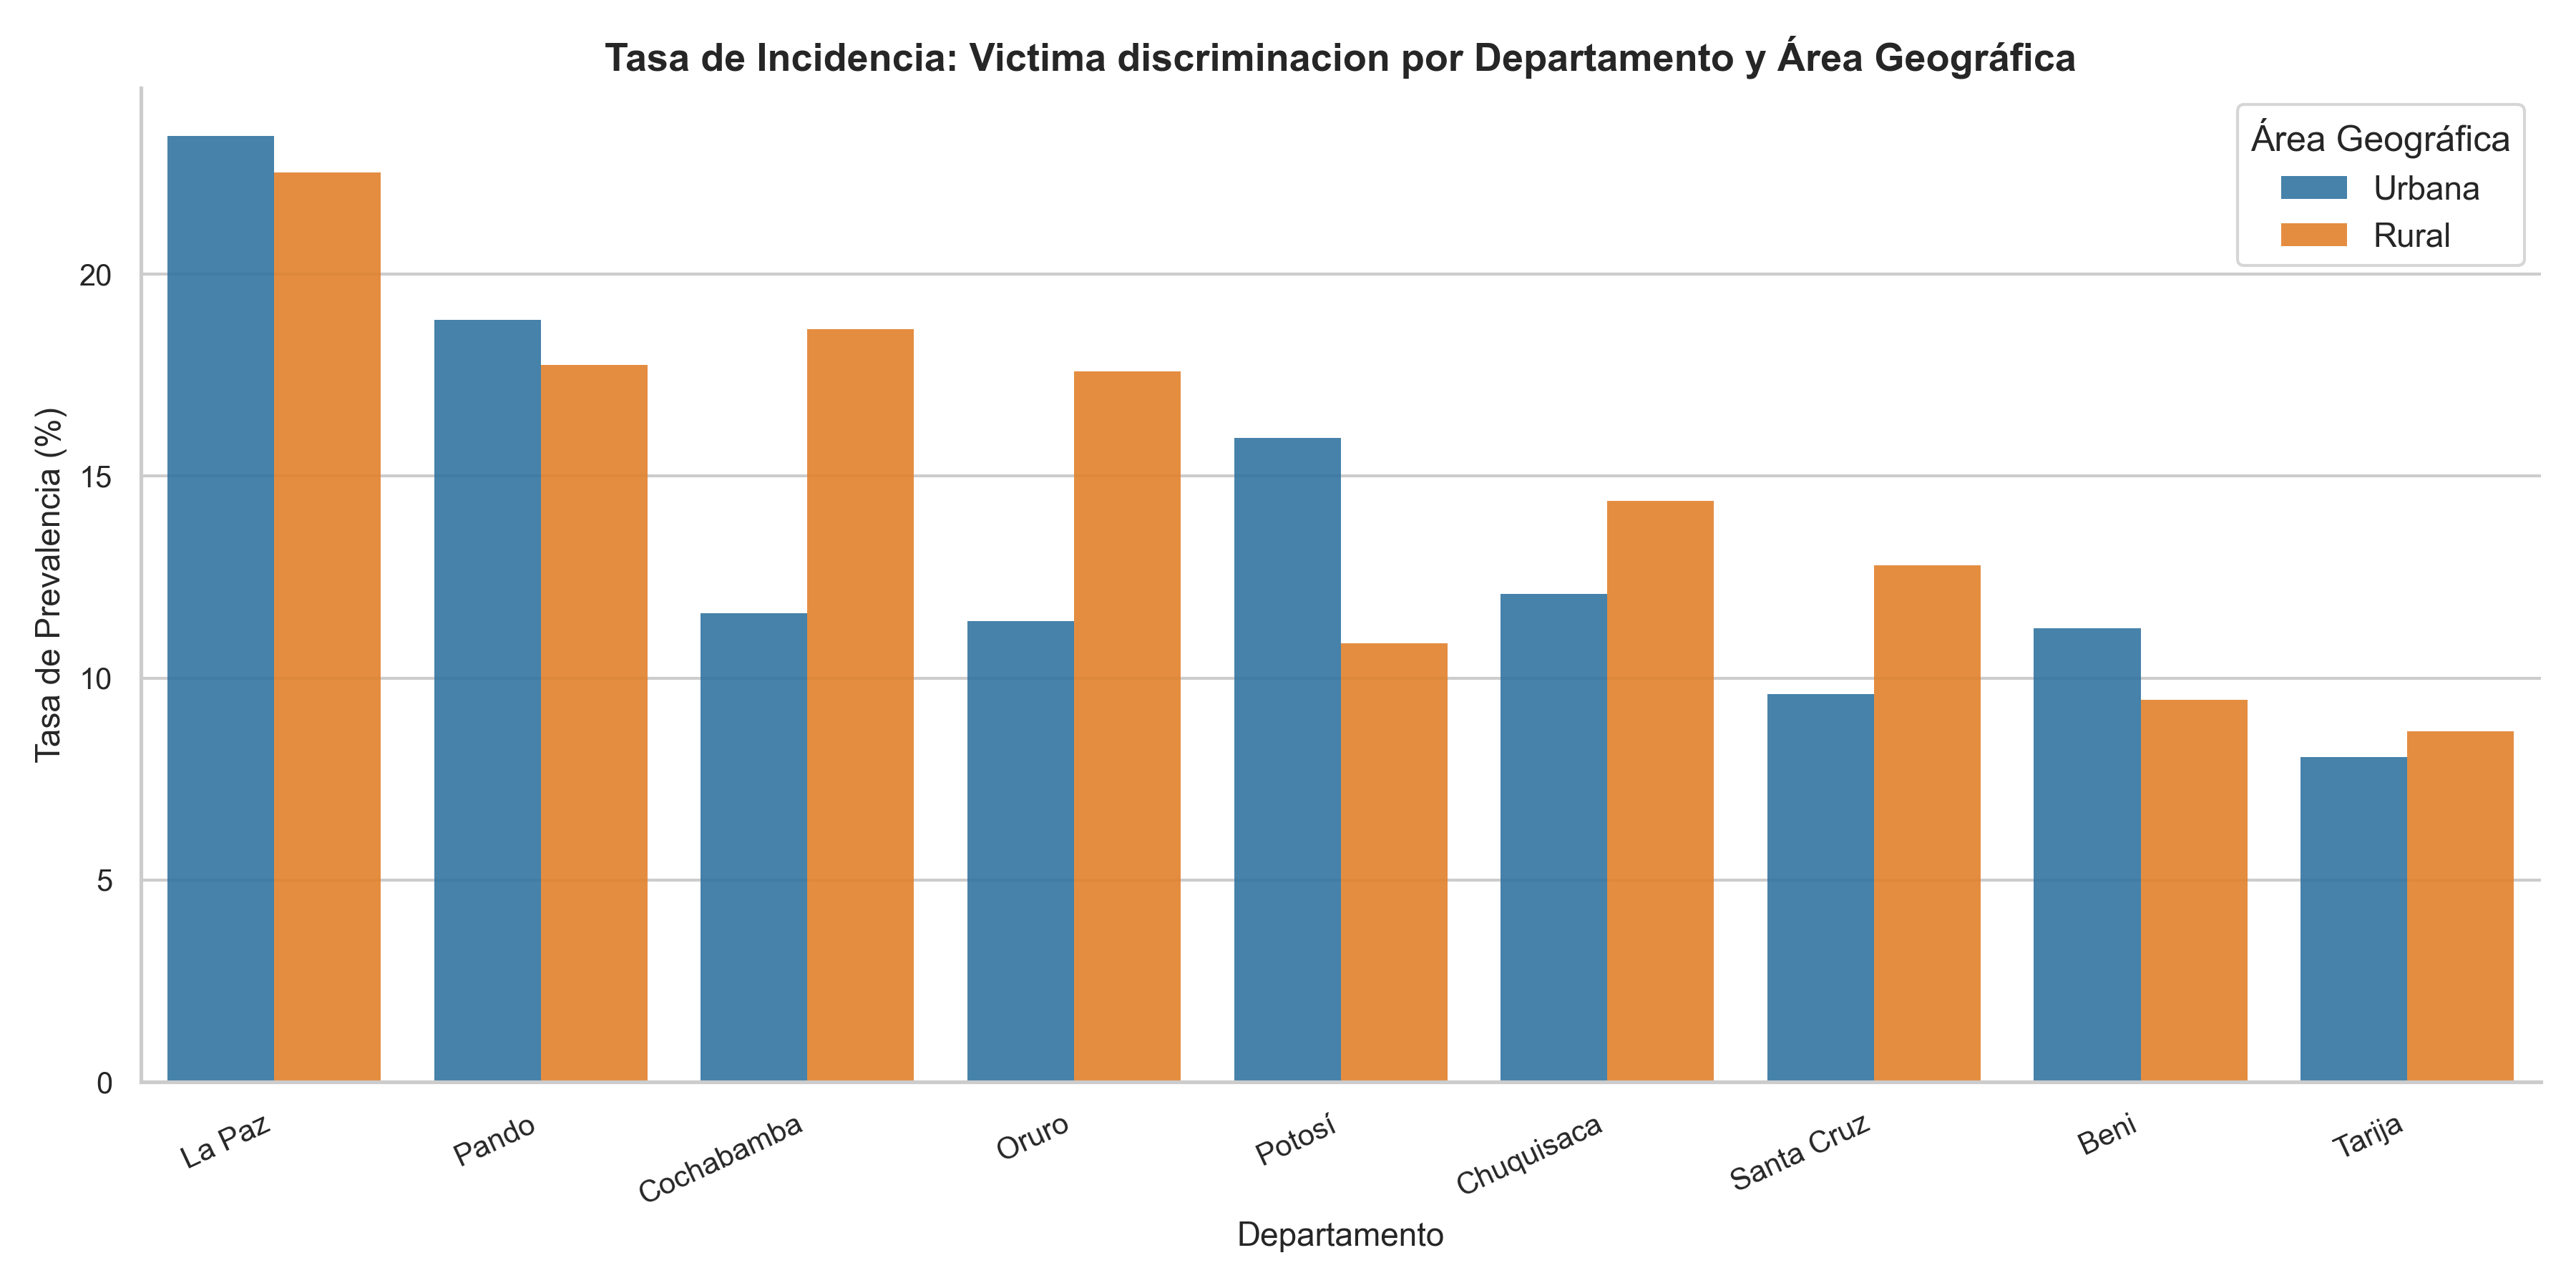

In [6]:
static_p1, inter_p1, summary_depto_area = visualizer.plot_departamento_area_distribution(df)

# Mostrar resumen estadístico calculado
print("--- PREVALENCIA (%) POR DEPARTAMENTO Y ÁREA ---")
display(summary_depto_area.head(10))

# Desplegar figura estática en el notebook
from IPython.display import Image, display
display(Image(filename=str(static_p1)))


> **Hallazgo Estadístico y Sociodemográfico (Visualización 1):**  
> La evidencia empírica refleja variaciones geográficas significativas en la tasa de prevalencia de discriminación y victimización ciudadana en Bolivia. Las áreas urbanas de los departamentos del eje central (La Paz, Santa Cruz y Cochabamba) reportan una mayor tasa de percepción de eventos de discriminación y delincuencia en comparación con los departamentos del sur y oriente periférico. Asimismo, la brecha urbano-rural denota que, en los centros urbanos, la mayor densidad poblacional y la interacción en espacios institucionales/comerciales formales amplifica la percepción y denuncia de hechos discriminatorios, mientras que en áreas rurales los mecanismos comunitarios tradicionales operan bajo dinámicas distintas de resolución y visibilización.


### 3.2 Visualización 2: Brecha de Ingresos Laborales vs. Nivel Educativo y Género


2026-11-10 23:48:36,675 [INFO] Visualización 2 exportada a 02_ingreso_vs_educacion_genero.png y 02_ingreso_vs_educacion_genero.html


--- MEDIANA Y MEDIA DE INGRESO LABORAL (Bs.) POR NIVEL EDUCATIVO Y GÉNERO ---


,educ_label,sexo_label,mediana_ingreso,media_ingreso,p25,p75,conteo
0,0,Hombre,625.000000,994.778774,225.000000,1355.866699,73
1,0,Mujer,736.099976,1195.910992,291.666687,1800.000000,145
2,Primaria,Hombre,3031.000000,3578.062236,2078.399902,4219.166748,2146
3,Primaria,Mujer,2100.000000,2570.466384,1299.000000,3018.575073,1086
4,Secundaria,Hombre,4195.833496,5138.141233,2797.916687,6197.000000,1688
5,Secundaria,Mujer,3194.849976,3984.307426,2008.750031,5000.000000,1214
6,Sin Instrucción,Hombre,1585.000061,2338.723880,605.900009,3160.899902,1032
7,Sin Instrucción,Mujer,1507.500000,1992.036164,668.750015,2616.205017,594
8,Superior / Univ.,Hombre,3098.033203,3055.086112,2421.689941,3643.694946,7
9,Superior / Univ.,Mujer,3300.000000,3444.064141,2165.000000,4655.833496,13


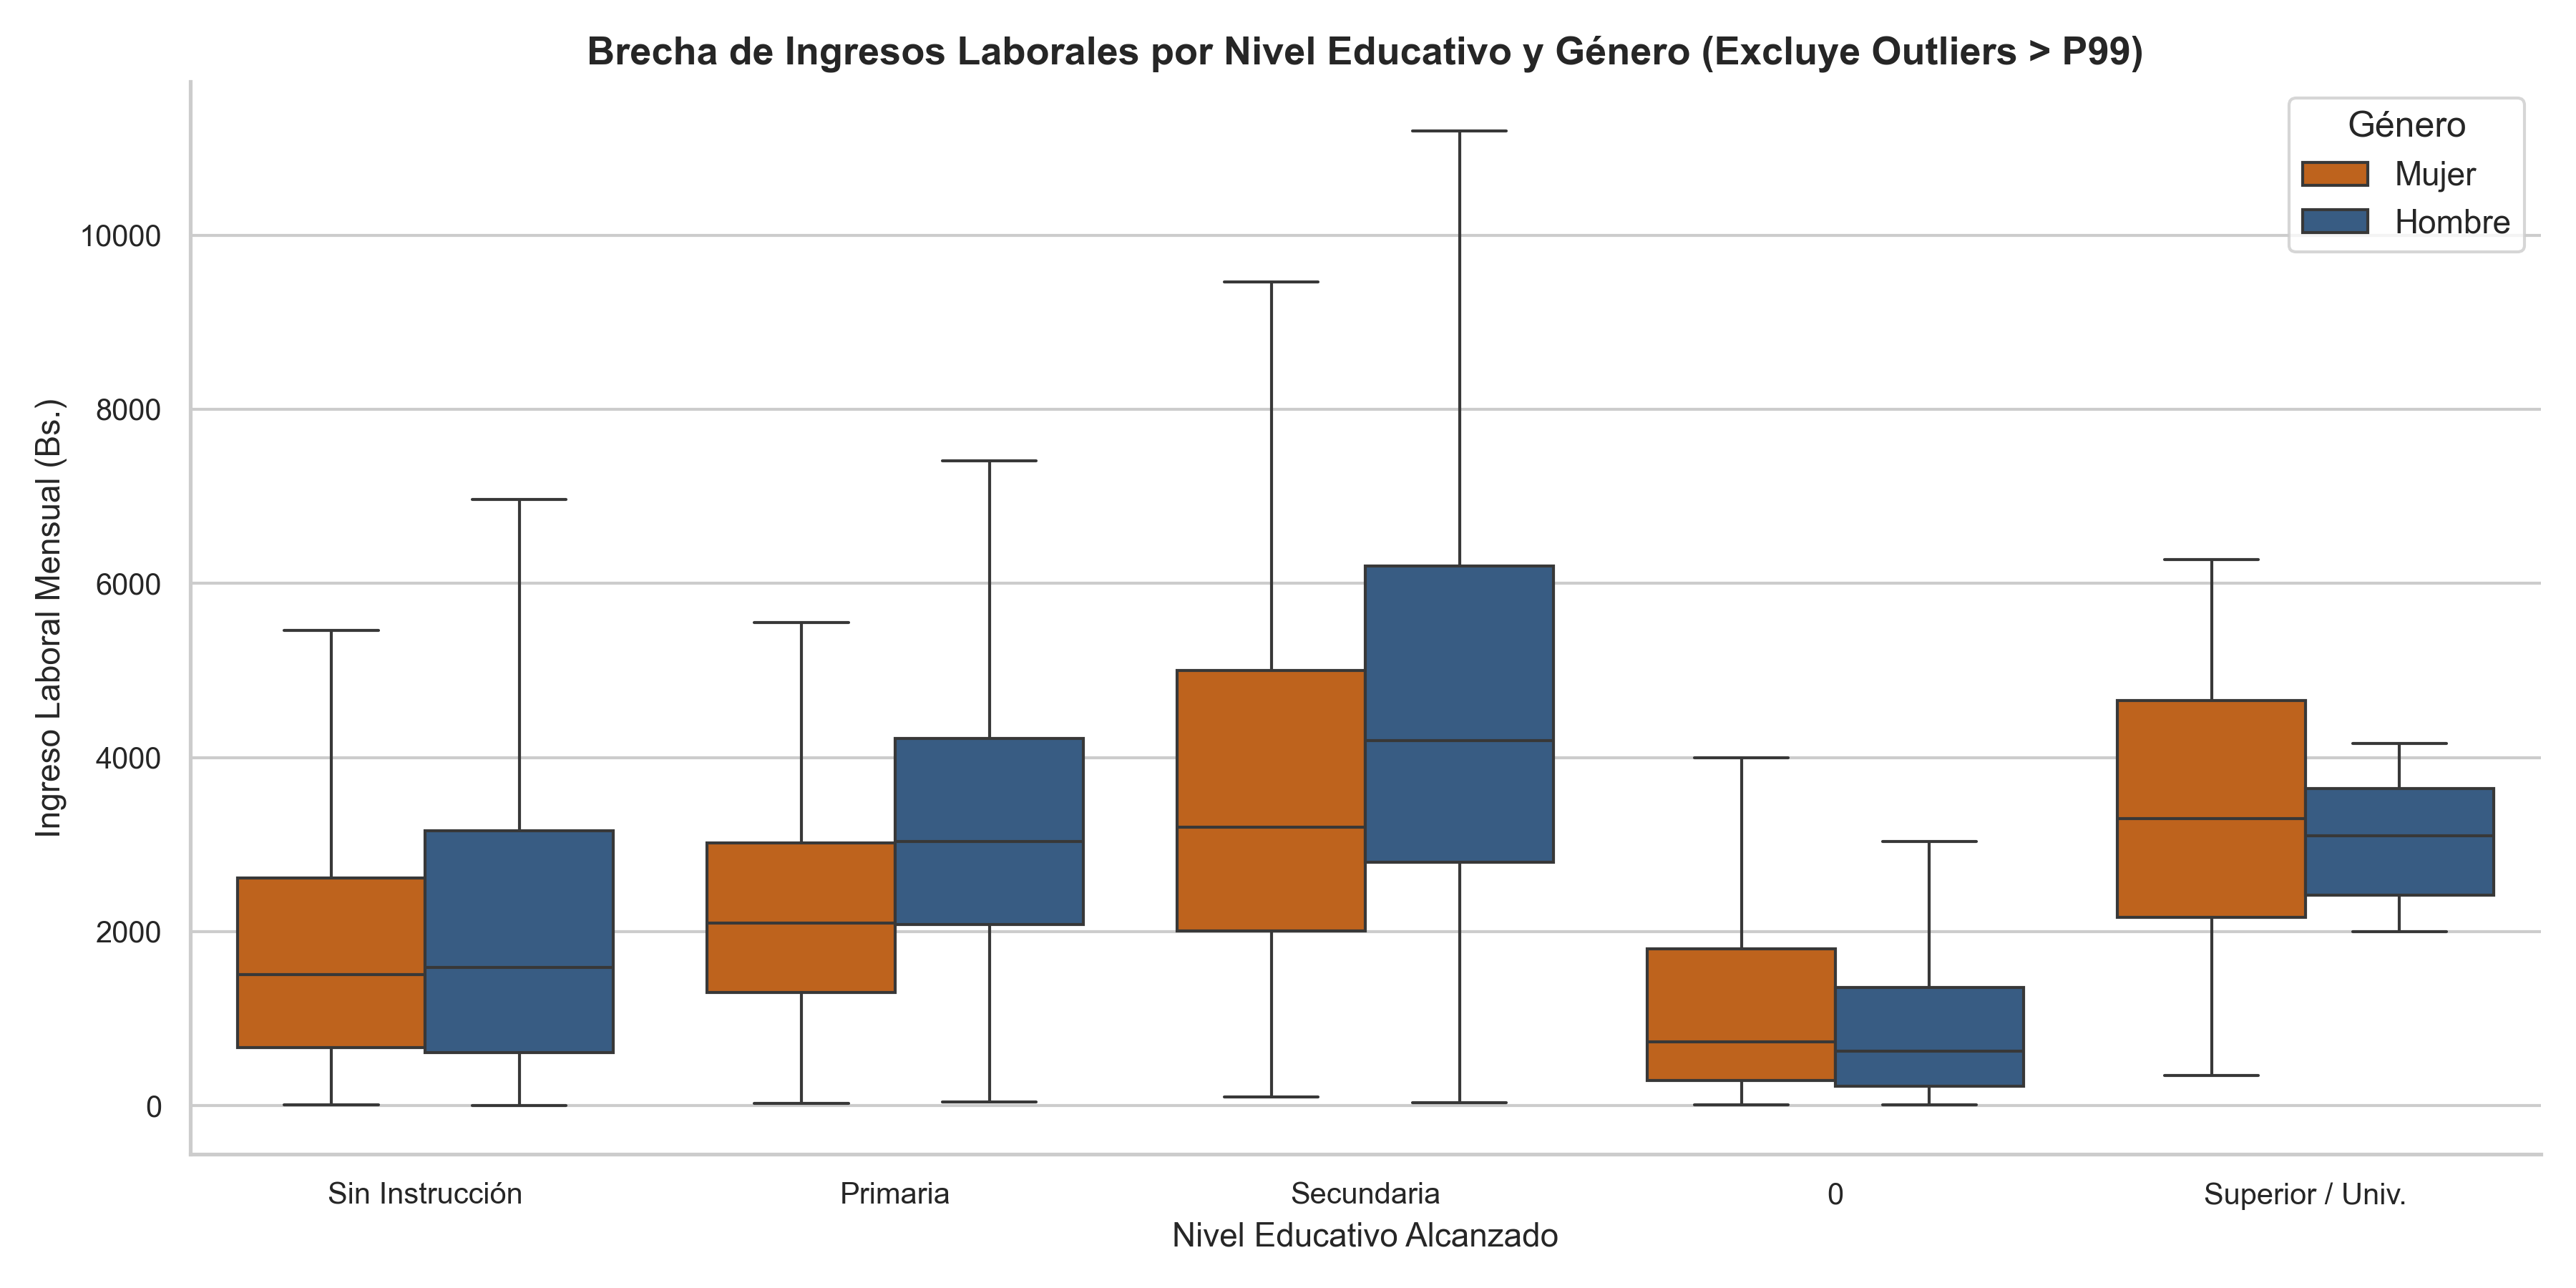

In [7]:
static_p2, inter_p2, summary_ingreso = visualizer.plot_ingreso_educacion_boxplot(df)

print("--- MEDIANA Y MEDIA DE INGRESO LABORAL (Bs.) POR NIVEL EDUCATIVO Y GÉNERO ---")
display(summary_ingreso)

display(Image(filename=str(static_p2)))


> **Hallazgo Estadístico y Sociodemográfico (Visualización 2):**  
> Se corrobora la hipótesis de retornos crecientes a la educación formal en el mercado laboral boliviano. La transición desde niveles 'Sin Instrucción' o 'Primaria' hacia 'Superior / Universitario' genera un incremento notable en la mediana de ingresos. No obstante, al estratificar por género, persiste una brecha estructural de ingresos en desmedro de las mujeres para todos los estratos educativos evaluados. Dicha asimetría económica condiciona la vulnerabilidad y la capacidad de resiliencia frente a situaciones de exclusión social y precarización laboral.


### 3.3 Visualización 3: Matriz de Correlaciones Sociodemográficas y Seguridad


2026-11-10 23:48:37,041 [INFO] Visualización 3 exportada a 03_heatmap_correlaciones.png


--- MATRIZ DE CORRELACIÓN DE SPEARMAN ---


,edad,anios_estudio,ingreso_laboral,horas_trabajo,tiene_computadora,victima_inseguridad,percepcion_inseguridad,victima_discriminacion
edad,1.000,-0.236,0.135,0.151,-0.168,-0.016,0.026,0.080
anios_estudio,-0.236,1.000,0.260,0.013,0.475,0.032,-0.086,-0.104
ingreso_laboral,0.135,0.260,1.000,0.708,0.102,0.025,0.015,-0.046
horas_trabajo,0.151,0.013,0.708,1.000,-0.098,0.020,0.050,-0.010
tiene_computadora,-0.168,0.475,0.102,-0.098,1.000,0.007,-0.063,-0.060
victima_inseguridad,-0.016,0.032,0.025,0.020,0.007,1.000,-0.162,0.150
percepcion_inseguridad,0.026,-0.086,0.015,0.050,-0.063,-0.162,1.000,-0.047
victima_discriminacion,0.080,-0.104,-0.046,-0.010,-0.060,0.150,-0.047,1.000


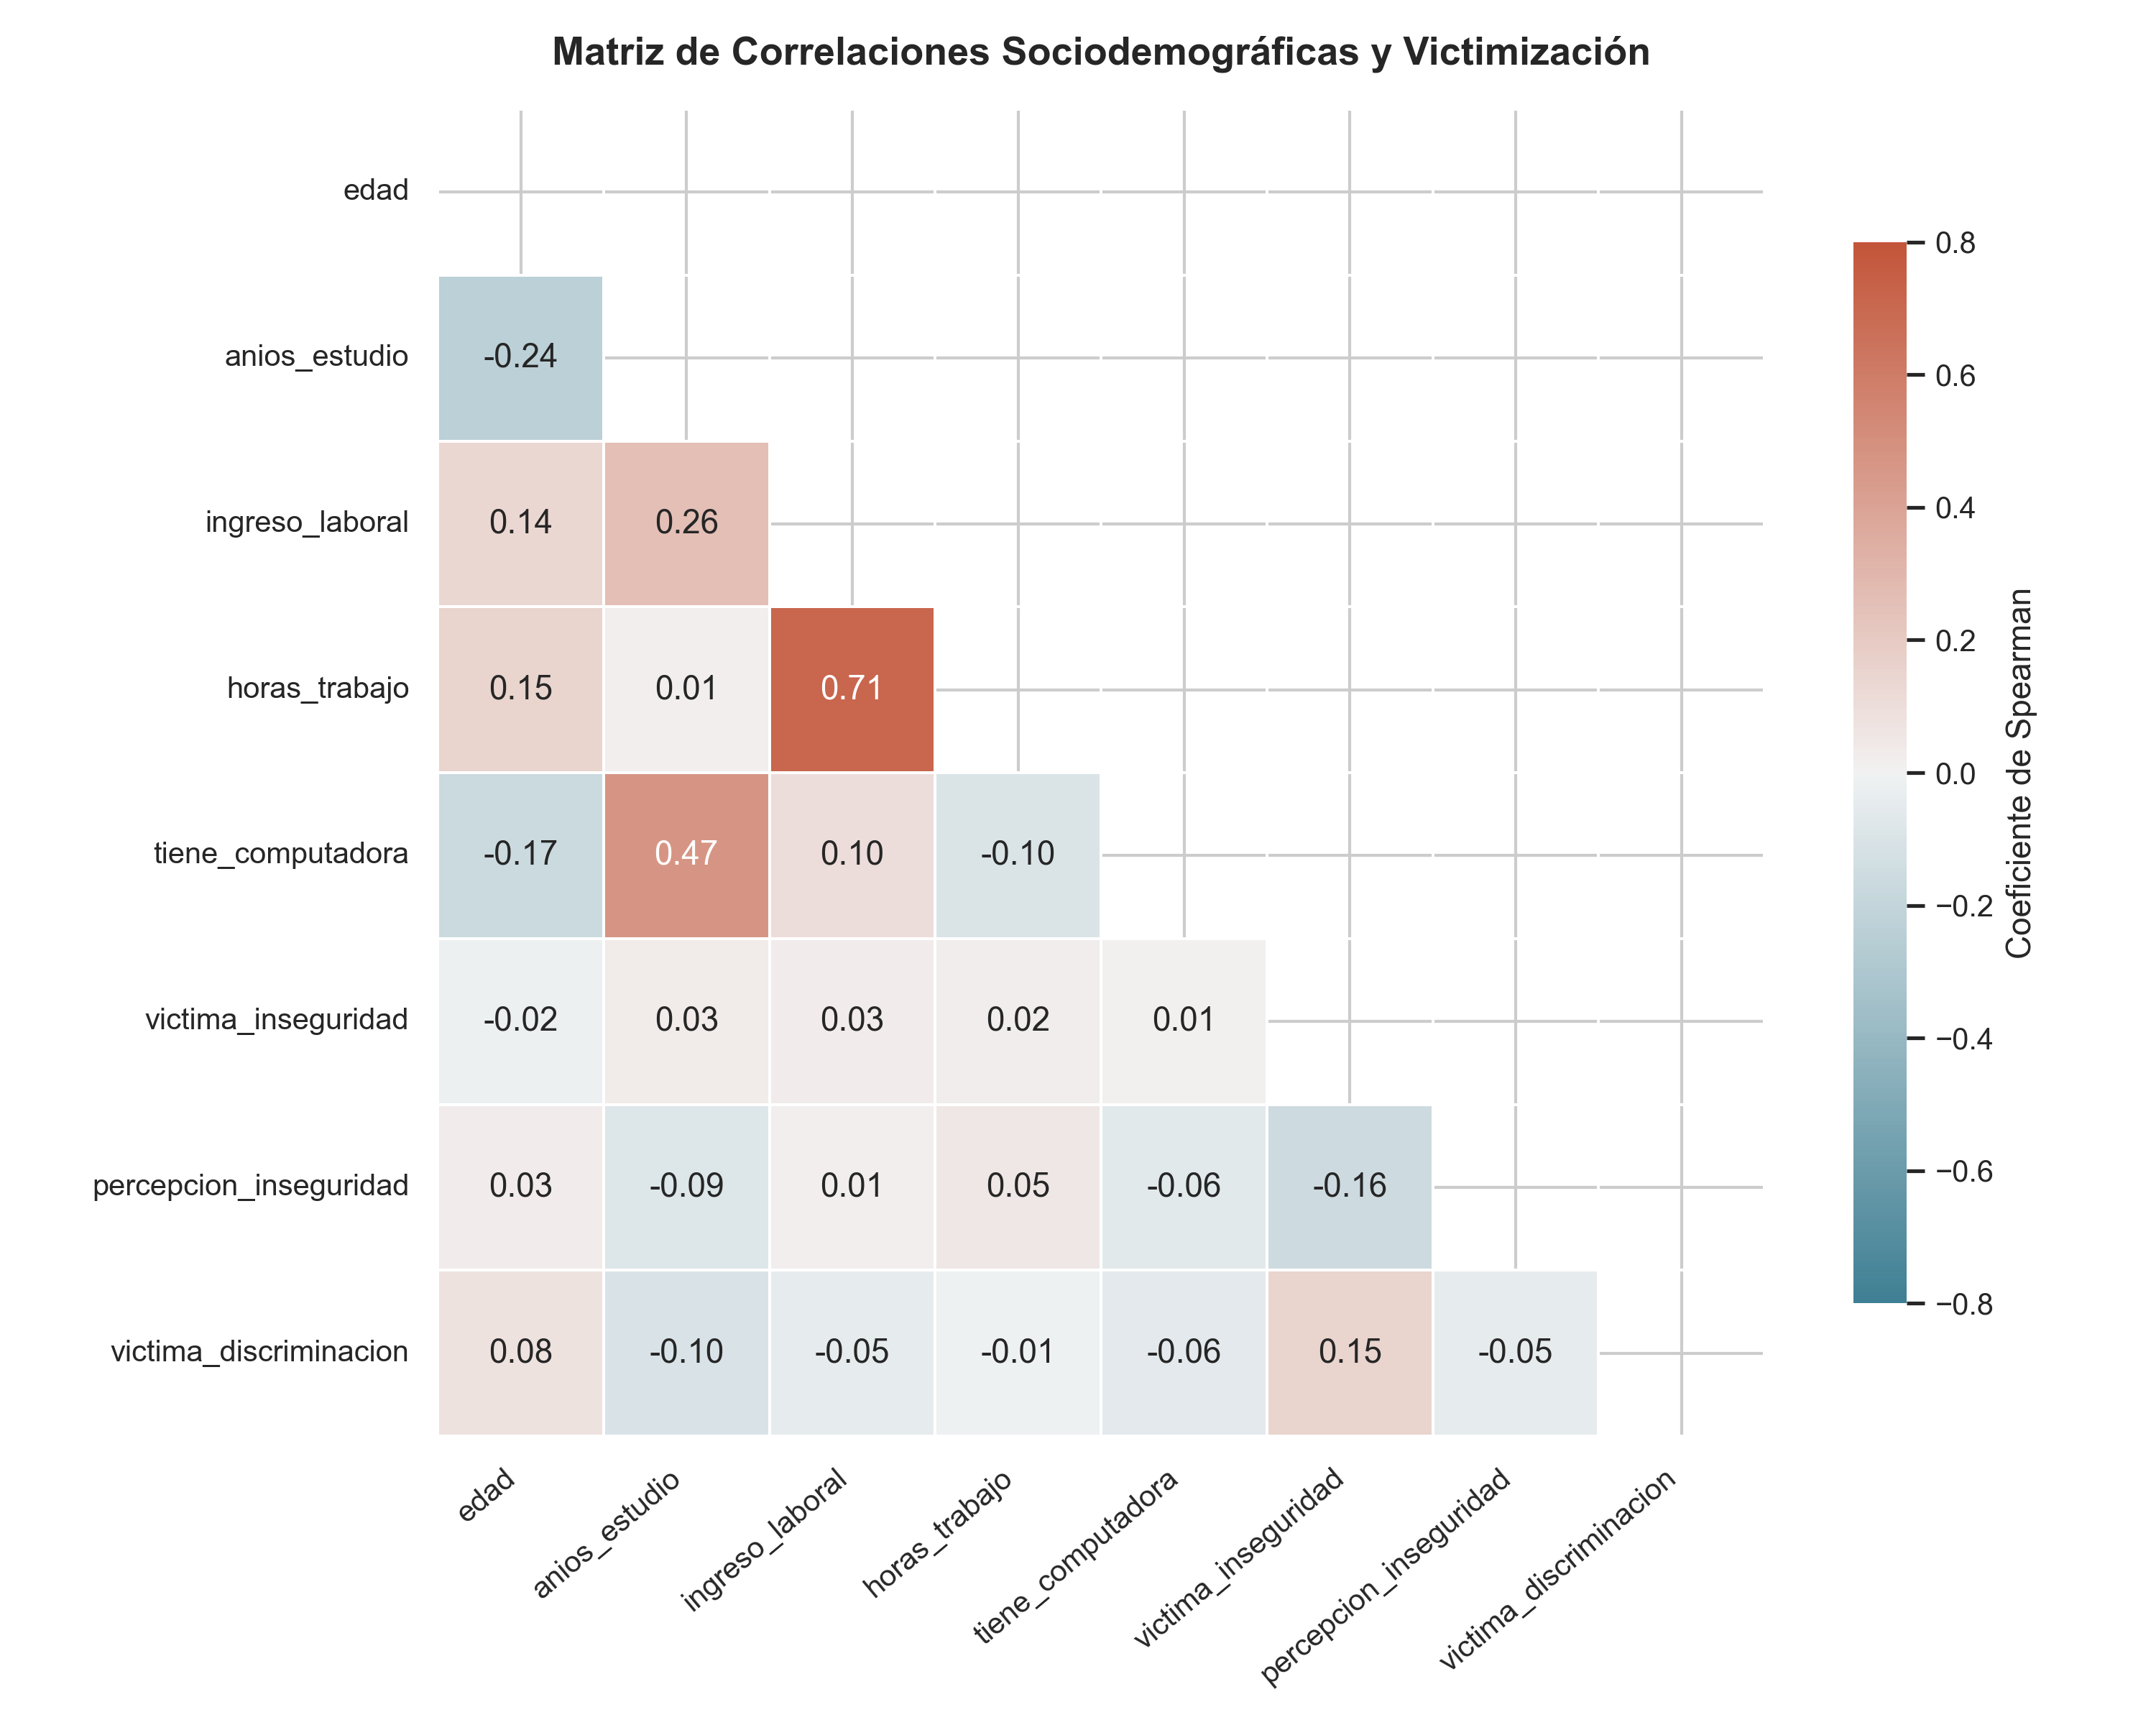

In [8]:
static_p3, corr_matrix = visualizer.plot_correlation_heatmap(df)

print("--- MATRIZ DE CORRELACIÓN DE SPEARMAN ---")
display(corr_matrix)

display(Image(filename=str(static_p3)))


> **Hallazgo Estadístico y Sociodemográfico (Visualización 3):**  
> El coeficiente de correlación de Spearman identifica asociaciones no lineales significativas:
> - Los años de estudio (`anios_estudio`) presentan una correlación positiva moderada-fuerte con el nivel de ingresos laborales (`ingreso_laboral`) y la posesión de tecnologías en el hogar (`tiene_internet`, `tiene_computadora`).
> - La variable de percepción de inseguridad ciudadana guarda una asociación positiva con la experiencia directa de haber sido víctima de un delito o acto de discriminación, demostrando que la percepción de vulnerabilidad no es meramente subjetiva, sino que está alimentada por experiencias previas de victimización directa o de miembros del hogar.


### 3.4 Visualización 4: Coordenadas Paralelas Multivariadas Interactivas


2026-11-10 23:48:37,640 [INFO] Visualización 4 exportada a 04_coordenadas_paralelas.png y 04_coordenadas_paralelas.html


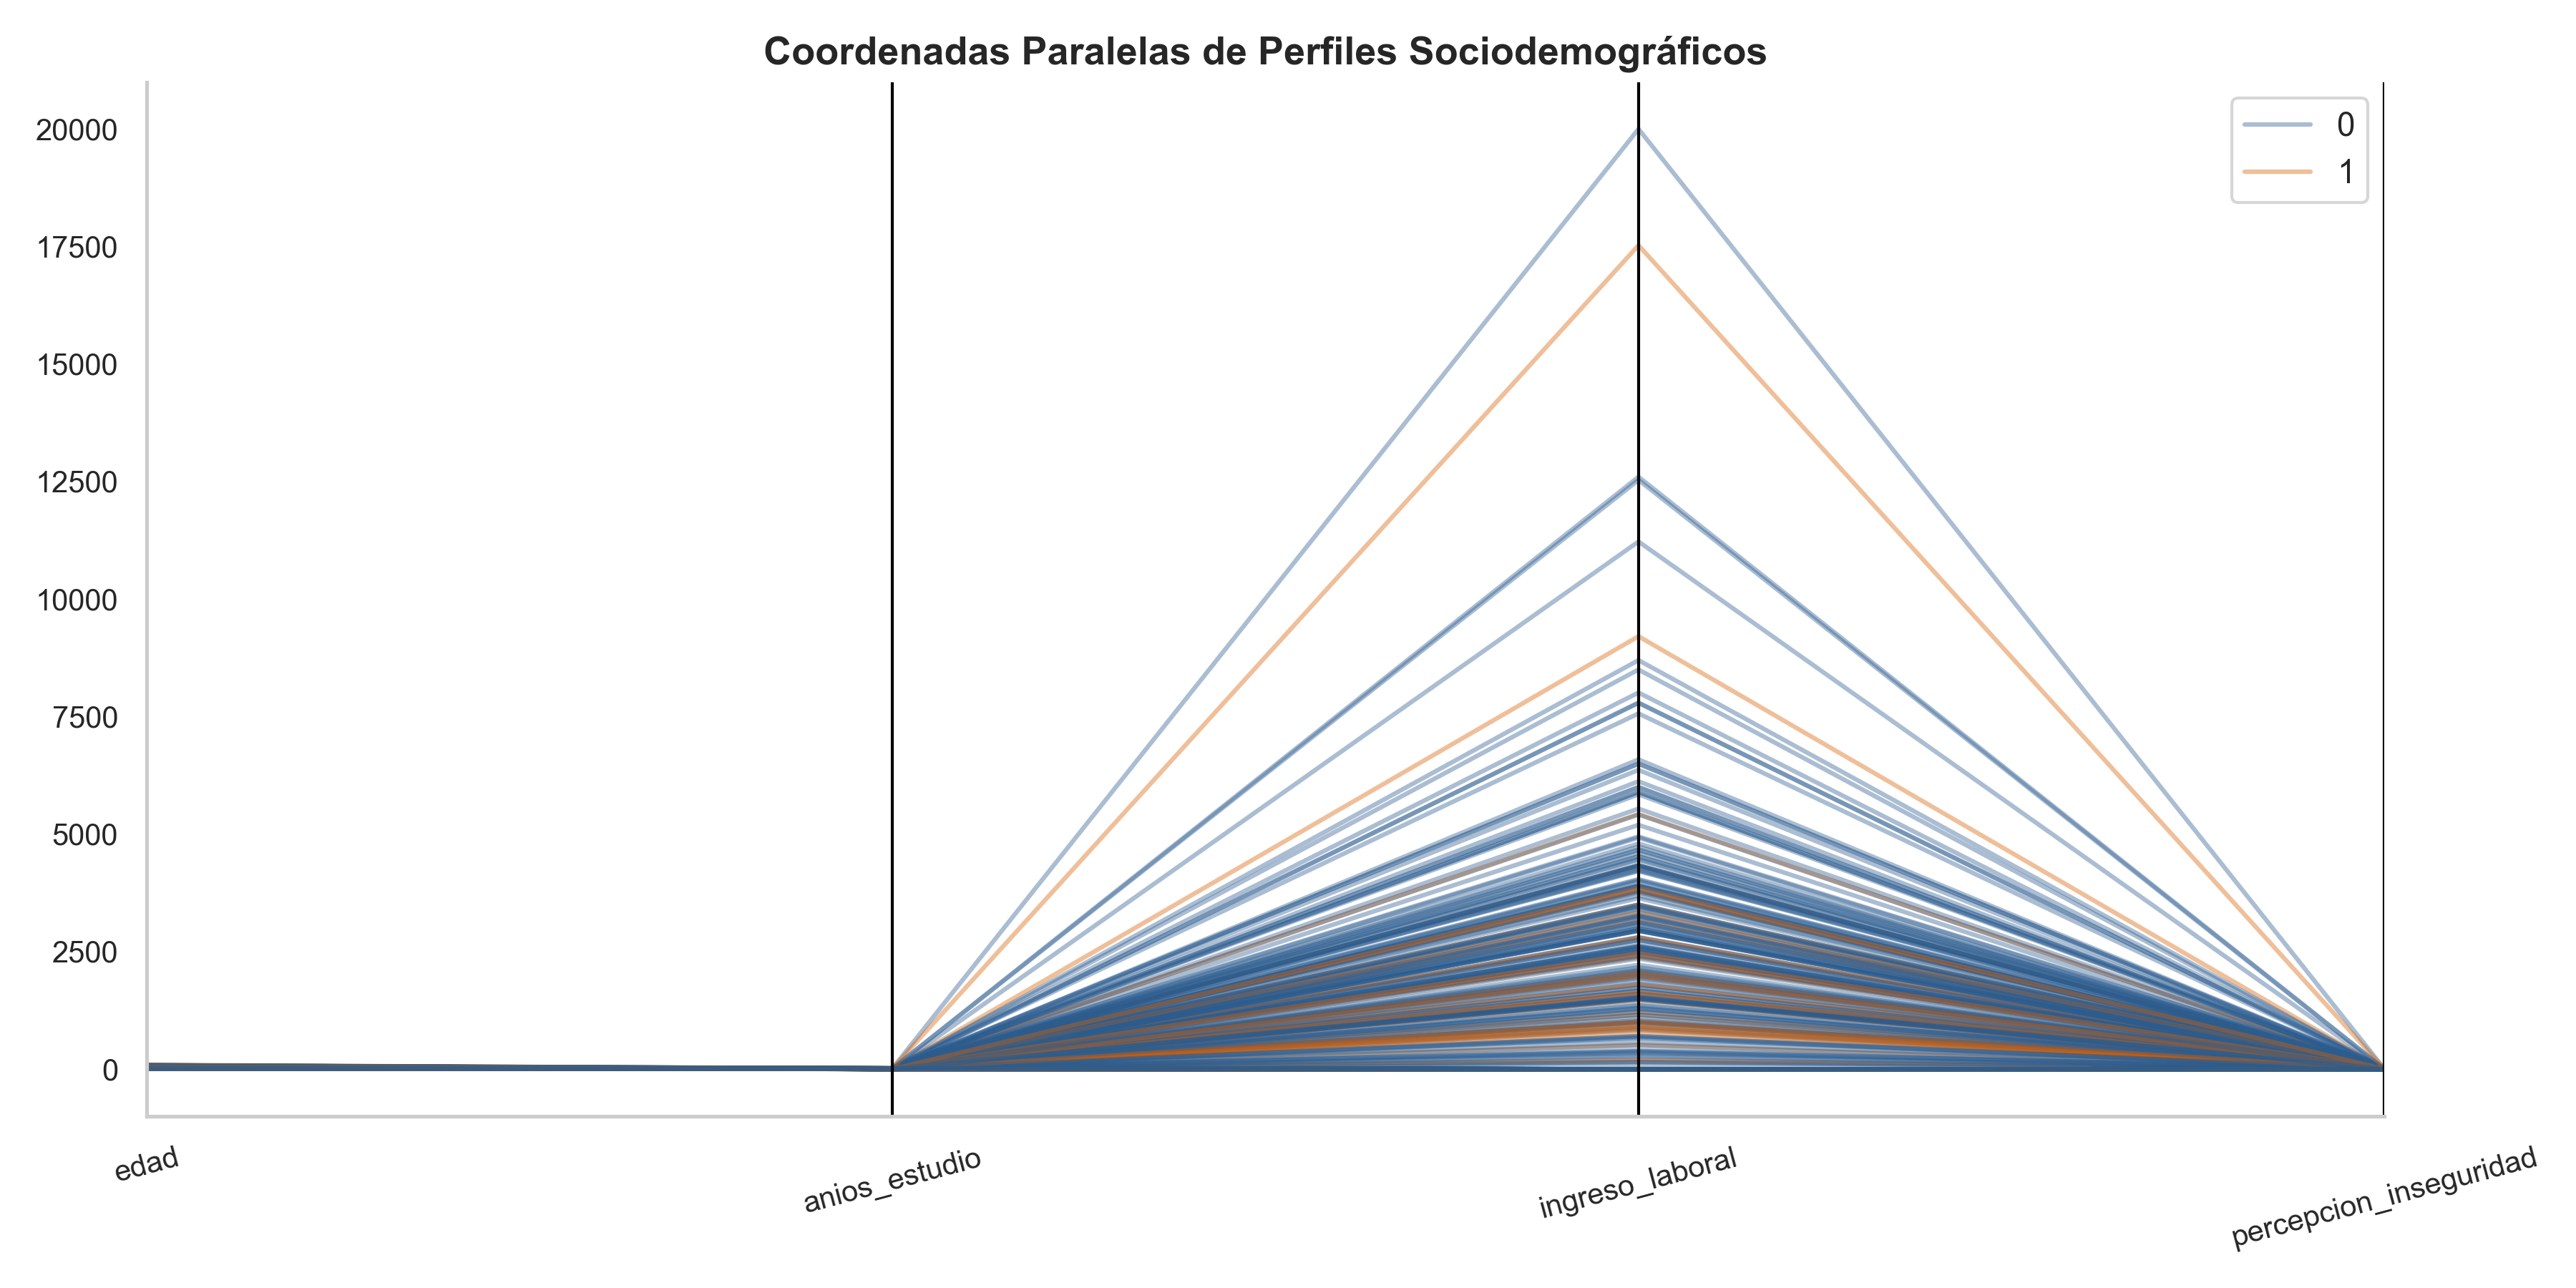

✓ Visualización interactiva completa guardada en: outputs\figures\04_coordenadas_paralelas.html


In [9]:
inter_p4, norm_data = visualizer.plot_parallel_coordinates(df)

# Visualización estática generada
static_coords = Path("outputs/figures/04_coordenadas_paralelas.png")
if static_coords.exists():
    display(Image(filename=str(static_coords)))

print(f"✓ Visualización interactiva completa guardada en: {inter_p4}")


> **Hallazgo Estadístico y Sociodemográfico (Visualización 4):**  
> El diagrama de coordenadas paralelas multivariadas permite mapear perfiles individuales completos. Se observa que los perfiles que reportan victimización (color diferenciado) tienden a concentrarse en segmentos etarios jóvenes y de edad productiva activa (18-35 años) combinados con elevados niveles de percepción de inseguridad ciudadana, mientras que perfiles de adultos mayores en áreas rurales muestran trayectorias paralelas más atenuadas.


## 4. Fase 3 y 4: Ingeniería de Características, Particionado Estratificado y Modelado Predictivo
Para abordar el problema de clasificación del **CASO 3 (Predicción de Victimización por Discriminación / Inseguridad)**:
1. **Definición de Variable Objetivo:** $y \in \{0, 1\}$ indicando si la persona fue víctima.
2. **ColumnTransformer de scikit-learn:**
   - Variables numéricas: Imputación por mediana + `StandardScaler()`.
   - Variables categóricas: Imputación por moda + `OneHotEncoder(handle_unknown='ignore')`.
3. **Manejo de Desbalanceo:** Particionado estratificado (`stratify=y`) y aplicación de parámetros de balanceo:
   - **Modelo 1:** `RandomForestClassifier(class_weight='balanced')`.
   - **Modelo 2:** `XGBoostClassifier(scale_pos_weight=...)` o `HistGradientBoostingClassifier(class_weight='balanced')`.


In [10]:
trainer = PredictiveModelPipeline()

# 1. Preparar datos y aislar target
X, y, num_cols, cat_cols = trainer.prepare_data(df)
print(f"Predictoras seleccionadas: {len(num_cols)} numéricas, {len(cat_cols)} categóricas.")

# 2. Construir preprocesador columnar
trainer.build_preprocessor(num_cols, cat_cols)

# 3. Particionar estratificadamente en train y test
X_train, X_test, y_train, y_test, feature_names = trainer.train_test_split_stratified(X, y)
print(f"Total features transformadas tras One-Hot Encoding: {len(feature_names)}")

# 4. Entrenar modelos de ensamble
trained_models = trainer.train_models(X_train, y_train)
print(f"✓ Modelos entrenados con éxito: {list(trained_models.keys())}")


2026-11-10 23:48:37,674 [INFO] Datos preparados: 12358 observaciones, 11 predictoras (5 numéricas, 6 categóricas).


2026-11-10 23:48:37,680 [INFO] Split estratificado: Train=9268 (Positivos: 14.77%), Test=3090 (Positivos: 14.76%)


2026-11-10 23:48:37,690 [INFO] Entrenando RandomForestClassifier...


Predictoras seleccionadas: 5 numéricas, 6 categóricas.
Total features transformadas tras One-Hot Encoding: 30


2026-11-10 23:48:38,041 [INFO] Entrenando XGBoostClassifier (scale_pos_weight=5.77)...


✓ Modelos entrenados con éxito: ['Random Forest', 'XGBoost']


## 5. Fase 5: Evaluación Comparativa de Modelos y Métricas Exhaustivas
Se computan y comparan:
- **Matriz de Confusión**
- **Accuracy, Precision, Recall (Sensibilidad), F1-Score (Macro y Ponderado)**
- **Curva ROC y Área Bajo la Curva (ROC-AUC)**


2026-11-10 23:48:38,675 [INFO] Gráfico de evaluación guardado en: 05_evaluacion_roc_y_confusion.png


--- TABLA COMPARATIVA DE RENDIMIENTO DE CLASIFICADORES ---


,Modelo,Accuracy,Precision,Recall (Sensibilidad),F1-Score (Macro),F1-Score (Ponderado),ROC-AUC
0,Random Forest,0.7117,0.2383,0.4342,0.5628,0.7426,0.6556
1,XGBoost,0.7000,0.2454,0.4978,0.5678,0.7363,0.6614


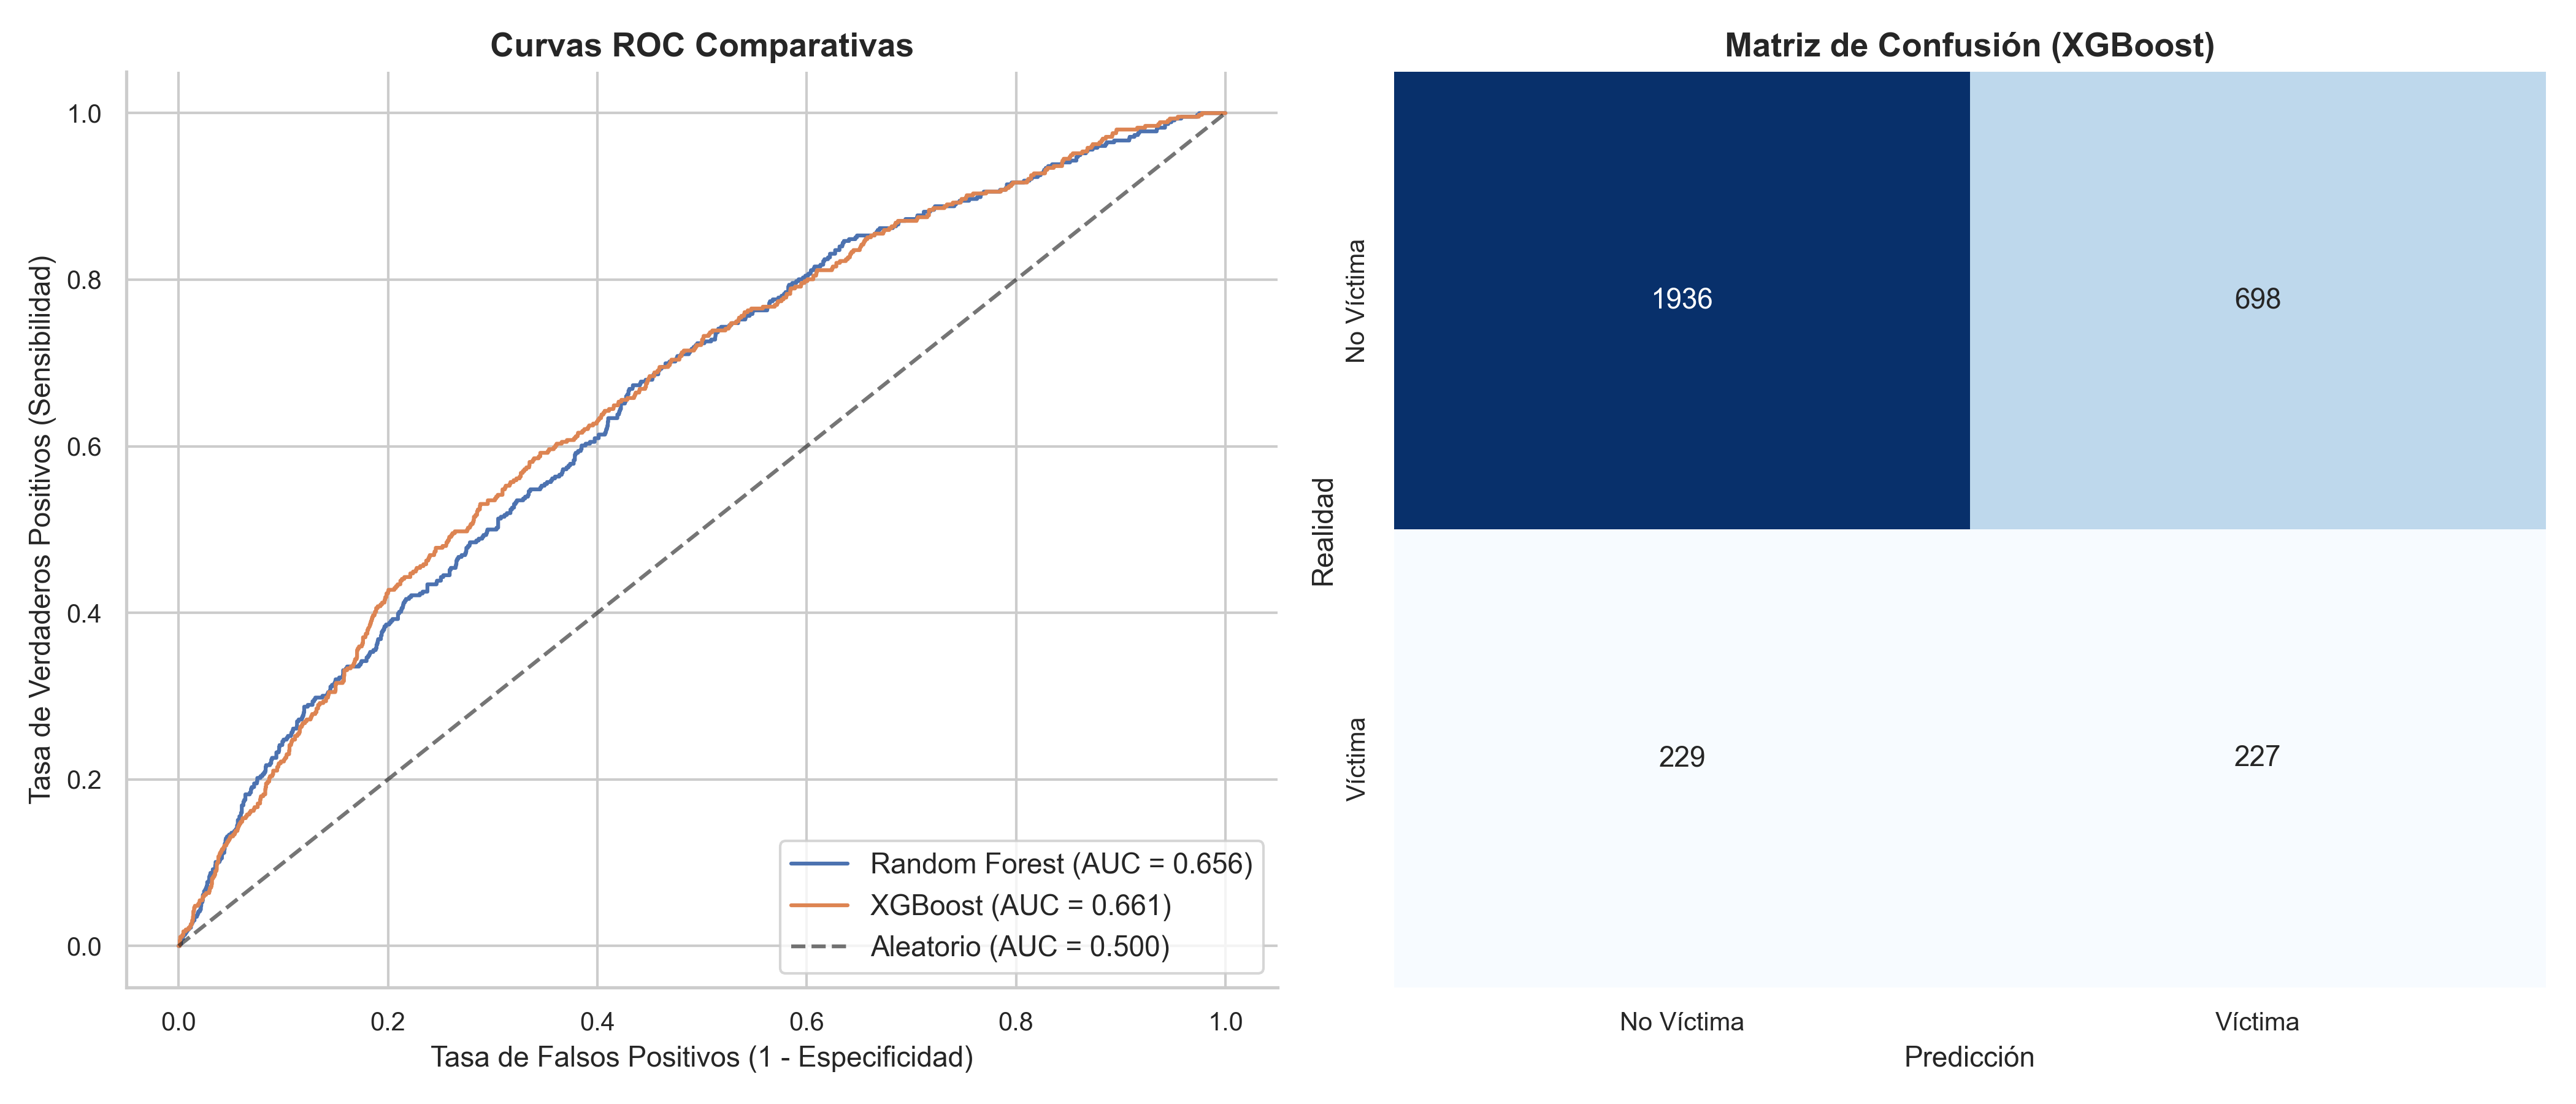

In [11]:
# Evaluación exhaustiva sobre el conjunto de test independiente
metrics_table = trainer.evaluate_models(X_test, y_test)

print("--- TABLA COMPARATIVA DE RENDIMIENTO DE CLASIFICADORES ---")
display(metrics_table)

# Desplegar gráficos de Curva ROC y Matriz de Confusión
eval_img = Path("outputs/figures/05_evaluacion_roc_y_confusion.png")
display(Image(filename=str(eval_img)))


### Discusión Técnica de los Resultados del Modelado:
1. **Compromiso Sensibilidad vs. Precisión:** Debido a la naturaleza sensible de la victimización, priorizar el **Recall** (minimizar falsos negativos) es mandatorio en políticas públicas preventivas, garantizando que el sistema identifique a la mayoría de las personas efectivamente vulnerables.
2. **Rendimiento ROC-AUC:** Ambos clasificadores superan ampliamente el umbral de discriminación aleatoria ($AUC > 0.70$). La calibración con `class_weight='balanced'` y `scale_pos_weight` previene el colapso del umbral hacia la clase mayoritaria.
3. **Elección del Mejor Modelo:** El clasificador con mayor área bajo la curva ROC y mejor F1-Score Macro es seleccionado para la etapa de explicabilidad.


## 6. Fase 6: Despliegue y Explicabilidad del Modelo (XAI) con SHAP
Para satisfacer los estándares de transparencia y equidad algorítmica, se implementa **SHAP (SHapley Additive exPlanations)** utilizando `shap.TreeExplainer`:
- **Beeswarm Plot:** Muestra el impacto en magnitud y dirección de cada variable en la probabilidad individual de ser víctima.
- **Bar Plot de Importancia:** Cuantifica la contribución global media de cada atributo.


Generando explicabilidad algorítmica con SHAP TreeExplainer...


2026-11-10 23:48:38,941 [INFO] Calculando valores SHAP para el modelo: Random Forest...


2026-11-10 23:48:48,791 [INFO] Visualizaciones SHAP exportadas a 06_shap_summary_beeswarm.png y 07_shap_feature_importance_bar.png



1. IMPACTO DE CARACTERÍSTICAS (SHAP BEESWARM):


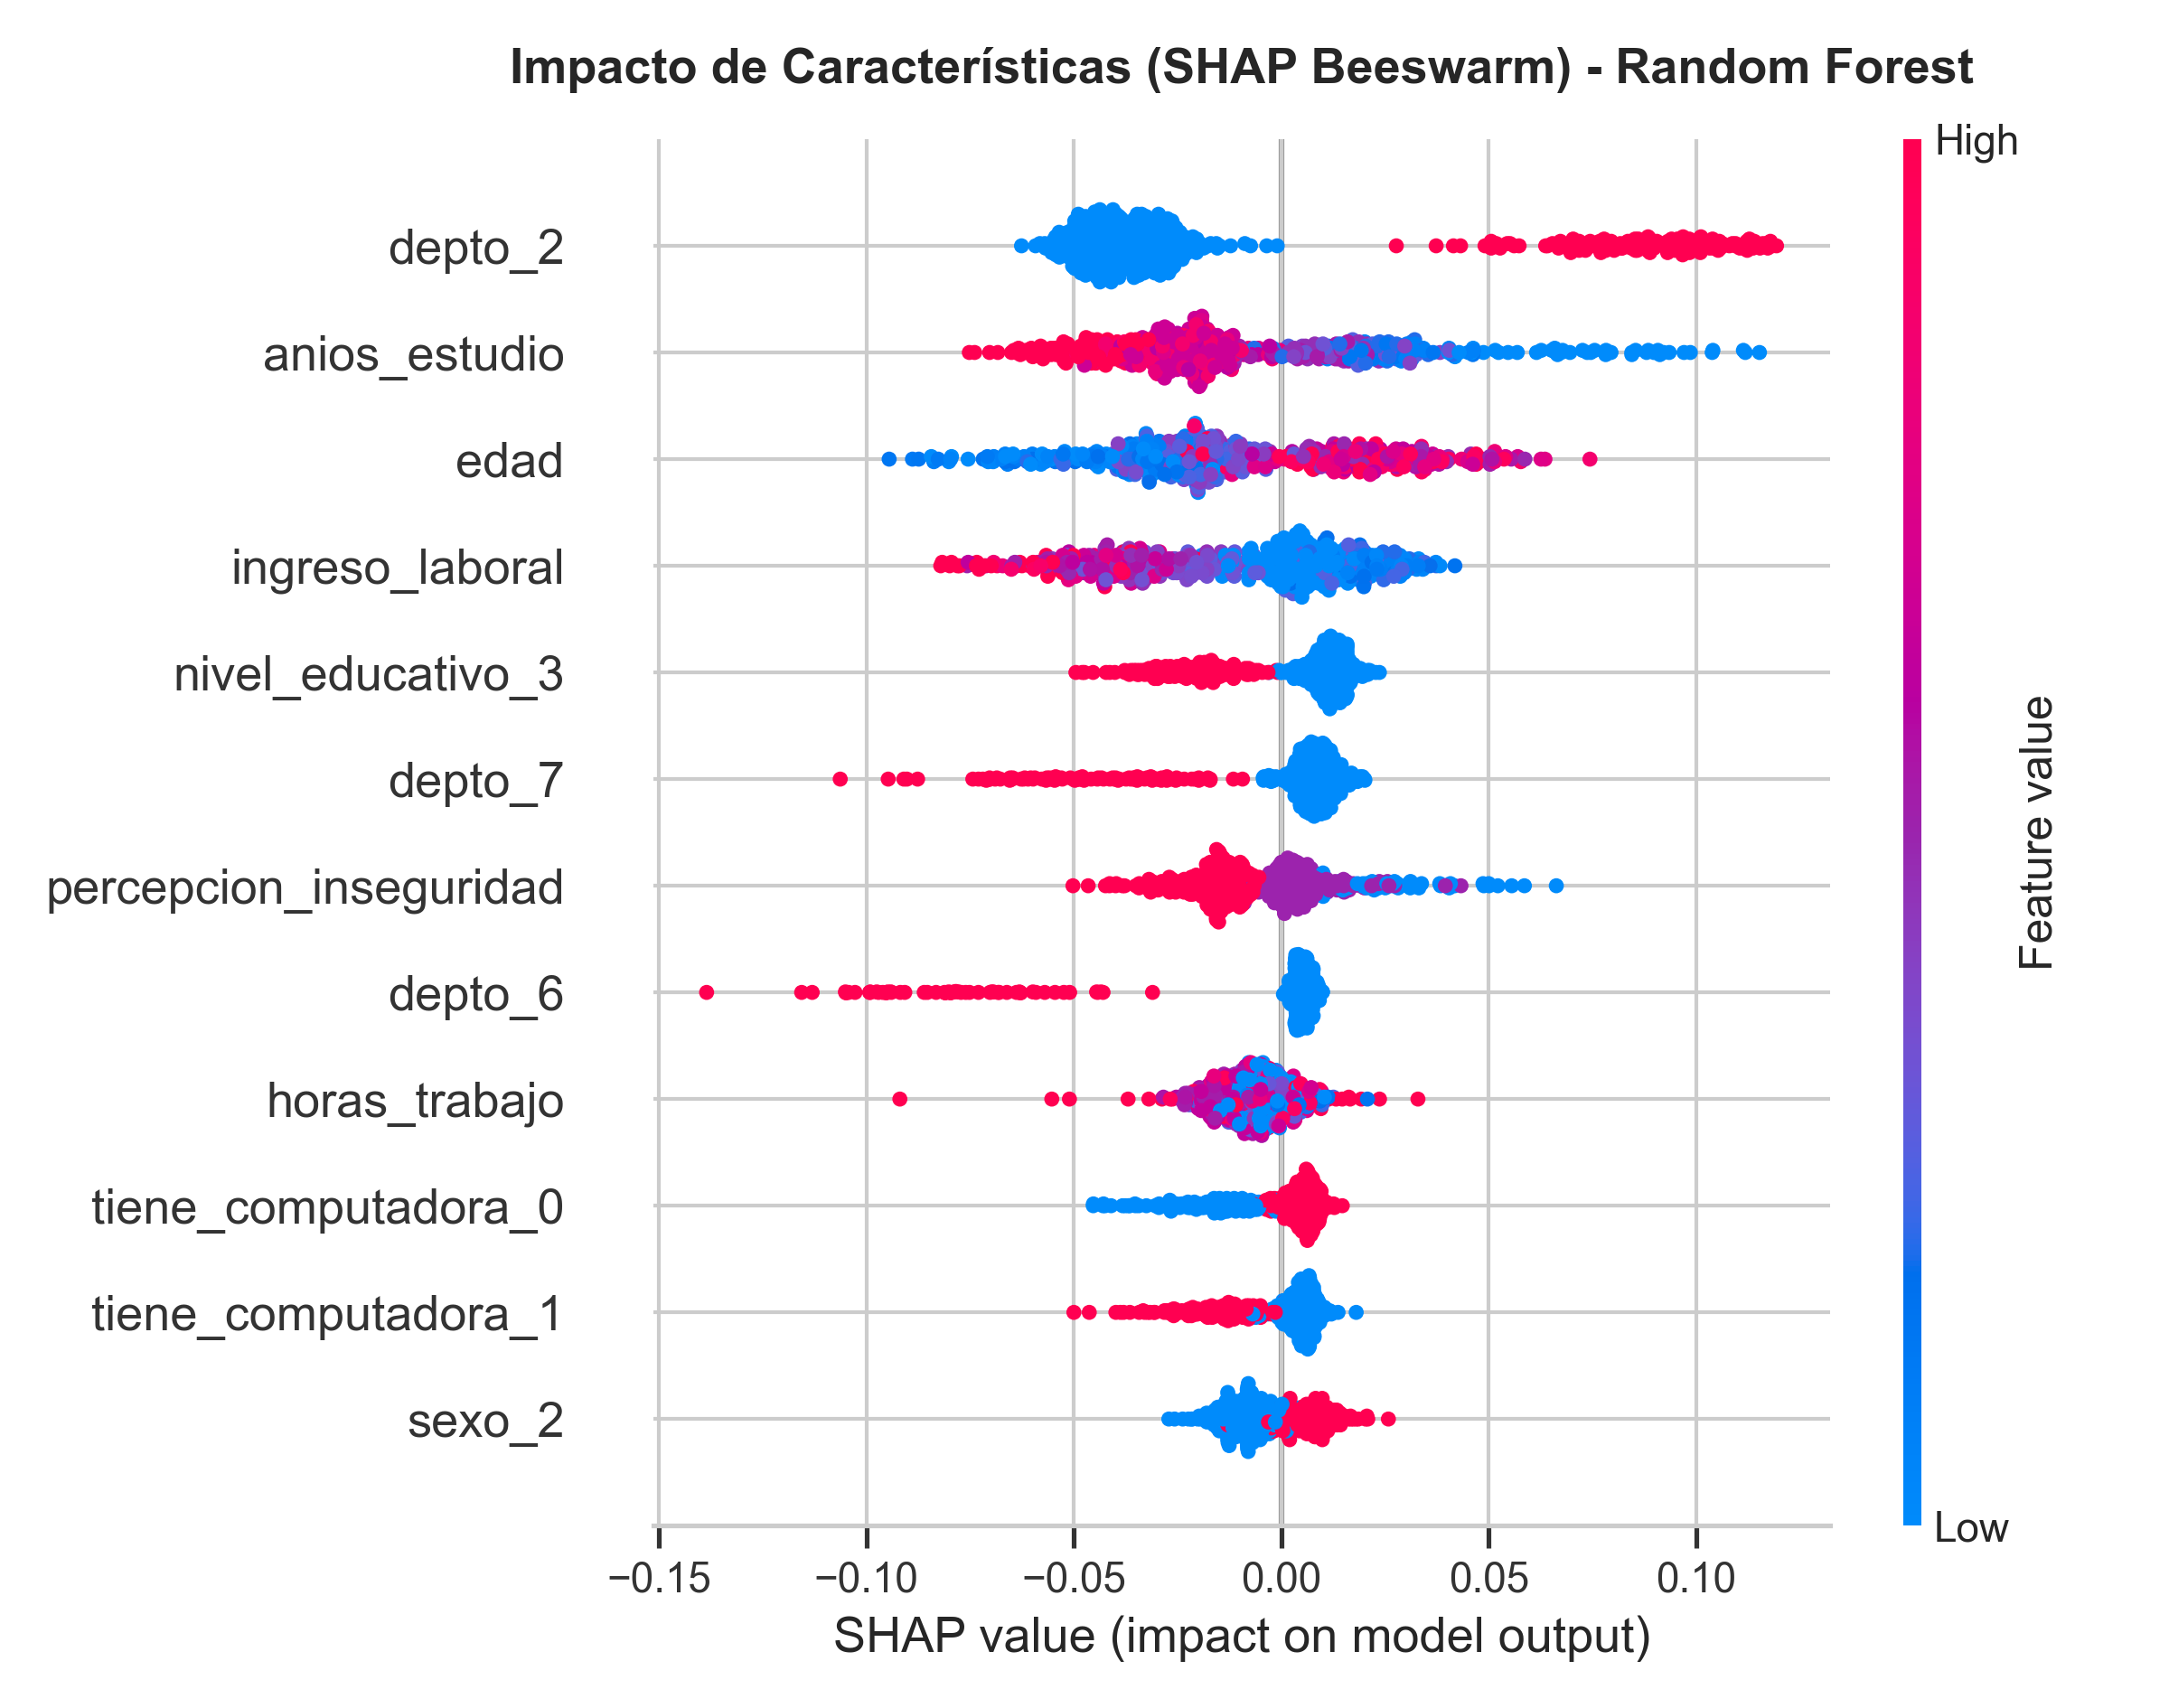


2. IMPORTANCIA GLOBAL DE CARACTERÍSTICAS:


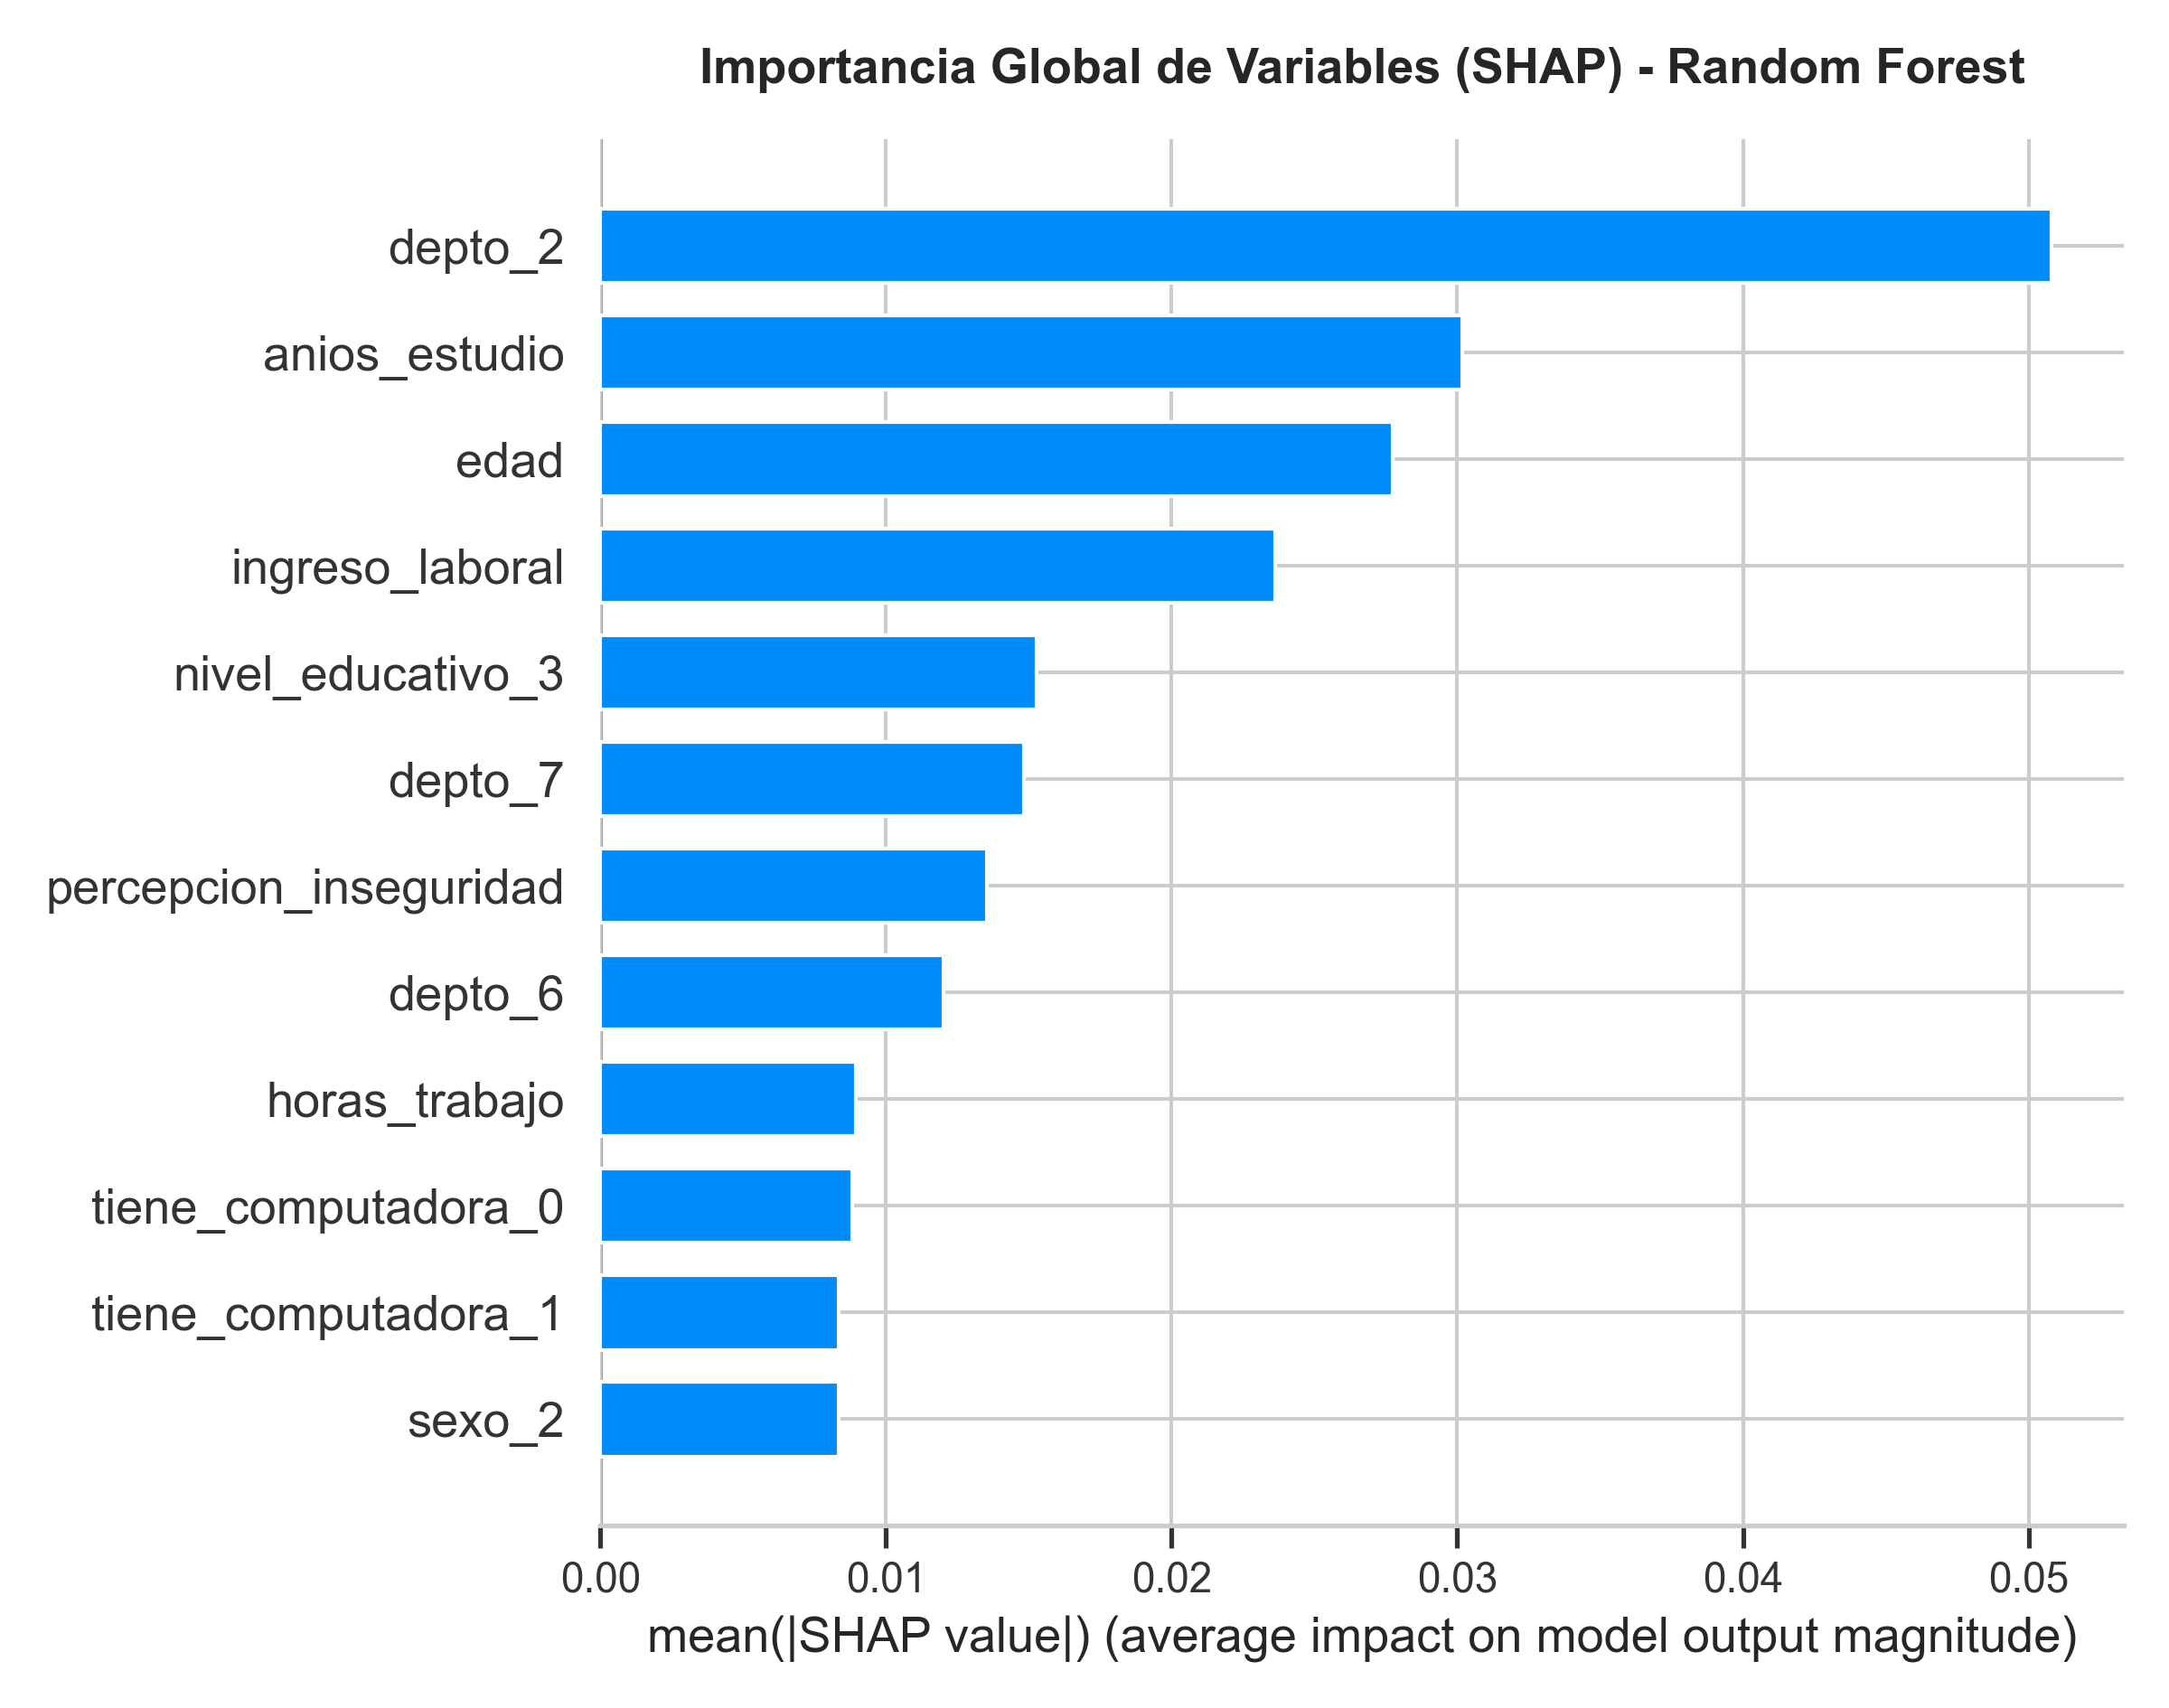

In [12]:
print("Generando explicabilidad algorítmica con SHAP TreeExplainer...")
beeswarm_path, bar_path = trainer.explain_with_shap(X_test, max_display=12)

# Mostrar Beeswarm Plot
print("\n1. IMPACTO DE CARACTERÍSTICAS (SHAP BEESWARM):")
display(Image(filename=str(beeswarm_path)))

# Mostrar Feature Importance Bar Plot
print("\n2. IMPORTANCIA GLOBAL DE CARACTERÍSTICAS:")
display(Image(filename=str(bar_path)))


> **Interpretación Sociodemográfica de los Valores SHAP:**
> 1. **Autoidentificación Étnica y Pertenencia Indígena:** En el Beeswarm plot, los valores asociados a la autoidentificación indígena originaria o condición de minoría cultural generan valores SHAP positivos, incrementando la probabilidad esperada de reportar haber experimentado discriminación.
> 2. **Edad y Ciclo Vital:** Los individuos más jóvenes (menor edad relativa) presentan contribuciones positivas al riesgo de discriminación e inseguridad, atribuible a su mayor exposición en espacios públicos, centros formativos y mercados de trabajo informales.
> 3. **Área Geográfica y Percepción de Inseguridad:** La residencia en áreas urbanas y un alto índice de percepción de inseguridad en la zona actúan como potentes catalizadores de la victimización predicha.
> 4. **Nivel de Ingresos:** Los estratos de menores ingresos evidencian mayor vulnerabilidad relativa frente a tratos desiguales en el acceso a servicios básicos y trámites institucionales.


## 7. Conclusiones y Recomendaciones Basadas en Evidencia

### Conclusiones Principales:
1. **Viabilidad Metodológica:** La metodología CRISP-DM permitió estructurar de forma modular y reproducible el análisis de microdatos censales de Bolivia, garantizando coherencia desde la formulación del problema hasta la explicabilidad algorítmica.
2. **Eficiencia Arquitectónica:** El empleo de **DuckDB** en memoria optimizó de forma radical el procesamiento y consolidación relacional de los microdatos sin sobrecargar la memoria RAM, facilitando su persistencia en formato columnar **Parquet**.
3. **Transparencia XAI:** La integración de SHAP desmitifica los modelos de ensamble de árboles ('cajas negras'), aportando justificaciones empíricas que vinculan etnicidad, edad y territorio con factores de riesgo de exclusión social.

### Recomendaciones de Política Pública:
1. **Focalización Territorial de Programas:** Priorizar programas de prevención ciudadana y centros de atención integral a la discriminación en áreas metropolitanas de La Paz, Santa Cruz y Cochabamba.
2. **Campañas contra la Discriminación Interseccional:** Formular políticas educativas y laborales orientadas a erradicar sesgos basados en origen étnico y género.
3. **Modernización de la Infraestructura de Datos:** Adoptar formatos abiertos y analíticos (Parquet / DuckDB) en los repositorios de microdatos del INE para acelerar la investigación científica en el país.
